# Projet Final : Adverserial Attack par CTGAN

## Imports & Data

In [1]:
!pip install ctgan imbalanced-learn xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from collections import defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, accuracy_score
)
from imblearn.over_sampling import SMOTE
import xgboost as xgb
from ctgan import CTGAN

# ── Config ──────────────────────────────────────────
SEED   = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)
np.random.seed(SEED)

print(f'Device : {DEVICE}')
print('Imports OK ✓')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.5/74.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 52.5 MB/s eta 0:00:00
Device : cuda
Imports OK ✓


In [2]:
!pip install kaggle
from google.colab import files
files.upload()  # upload your kaggle.json API key
!mkdir ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d mlg-ulb/creditcardfraud --unzip

mv: cannot stat 'kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 110MB/s]



## Exploration et traîtement des données

In [4]:
original_df = pd.read_csv('creditcard.csv')

In [5]:
original_df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


- Les colones Vx sont le résultats d'une tranformation par PCA avant publication par Kaggle
- Les deux seules colones à traîter sont 'Time' & 'Amount'

In [6]:
print(f'Shape         : {original_df.shape}')
print(f'Fraud rate    : {original_df["Class"].mean()*100:.3f}%')
print(f'Missing vals  : {original_df.isnull().sum().sum()}')

Shape         : (284807, 31)
Fraud rate    : 0.173%
Missing vals  : 0


- Le jeu de données comprends plus de 280k données
- Pourtant, seulement 0.173% sont des fraudes (très grand débalancement)
- Aucune donnée manquante

In [7]:
#Scaling
std_scaler = StandardScaler()
original_df['Amount'] = std_scaler.fit_transform(original_df['Amount'].values.reshape(-1, 1))
original_df['Time'] = std_scaler.fit_transform(original_df['Time'].values.reshape(-1, 1))

In [8]:
#Train & Test split avec stratify pour garder les mêmes proportions dans test and train

X = original_df.drop('Class', axis=1)
y = original_df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y #80/20
)
print(f'Train: {X_train.shape[0]} | Test: {X_test.shape[0]}')

Train: 227845 | Test: 56962


In [9]:
#Balancement des données d'entrainement par SMOT
sm = SMOTE(random_state=SEED)

X_bal, y_bal = sm.fit_resample(X_train, y_train)
print(f'Shape of balanced data   : {X_bal.shape}')

Shape of balanced data   : (454902, 30)


## Entrainement de XGBOOST & RandomForest

### XGBOOST

In [ ]:
#------------XGBOOST--------------

#Initialisation
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=SEED,
    n_jobs=-1
)

#Entrainement et évaluation
xgb_model.fit(X_bal, y_bal, eval_set=[(X_test, y_test)], verbose=False)

#Statistiques
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_preds = (xgb_probs > 0.5).astype(int)
xgb_acc   = accuracy_score(y_test, xgb_preds)
xgb_auc   = roc_auc_score(y_test, xgb_probs)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [19:31:12] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
print('-' * 60)
print(f'XGBoost       →  Acc: {xgb_acc:.4f} | AUC: {xgb_auc:.4f}')
print('-' * 60)
print(classification_report(y_test, xgb_preds, target_names=['Legit', 'Fraud']))
print('-' * 60)

------------------------------------------------------------
XGBoost       →  Acc: 0.9984 | AUC: 0.9801
------------------------------------------------------------
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00     56864
       Fraud       0.52      0.88      0.65        98

    accuracy                           1.00     56962
   macro avg       0.76      0.94      0.83     56962
weighted avg       1.00      1.00      1.00     56962

------------------------------------------------------------


- On constate que XGBOOST est hyperperformant avec une accuracy de 99.8% et un AUC de 0.98

- On voit un très bon recall de 0.88 (88% des fraudes sont détectées)

- La précision est toute fois mauvaise (52% de toutes les des inputs prédit comme frause le sont réelement)

###RandomForest

In [ ]:
#------------RandomForest--------------

#Initialisation
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=SEED
)

#Entrainement
rf_model.fit(X_bal, y_bal)

#Statistique
rf_probs = rf_model.predict_proba(X_test)[:, 1]
rf_preds = (rf_probs > 0.5).astype(int)
rf_acc   = accuracy_score(y_test, rf_preds)
rf_auc   = roc_auc_score(y_test, rf_probs)

In [ ]:
print('-' * 60)
print(f'Random Forest →  Acc: {rf_acc:.4f} | AUC: {rf_auc:.4f}')
print('-' * 60)
print(classification_report(y_test, rf_preds, target_names=['Legit', 'Fraud']))
print('-' * 60)

------------------------------------------------------------
Random Forest →  Acc: 0.9990 | AUC: 0.9839
------------------------------------------------------------
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00     56864
       Fraud       0.67      0.85      0.75        98

    accuracy                           1.00     56962
   macro avg       0.83      0.92      0.87     56962
weighted avg       1.00      1.00      1.00     56962

------------------------------------------------------------


- Tout comme XGBOOST, RandomForest excelle avec une accuracy de 99.9% et un AUC de 0.98

- Le recall est tout aussi bon avec 0.85

- On obtien une meilleur augmentation de la précison de l'ordre de 0.15 (0.52 -> 0.67)

## Entrainement du réseau de neurones

In [ ]:
# Simple MLP qu'on entrainera pour imiter le comportement de nos arbres

class SurrogateNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

In [ ]:
#Boucle d'entrînement du modèle

def train_surrogate(bb_model, X_train, X_test, y_test, name='Surrogate', epochs=50):

    print(f'  Training {name} surrogate...')

    # On recupère les prédiction du notre du modèle boite noire qui servirons
    # de groundtruth pour notre nn
    bb_labels = bb_model.predict_proba(X_train)[:, 1].astype(np.float32)

    #Préparation des données
    X_tr  = torch.tensor(X_train,    dtype=torch.float32)
    y_bb = torch.tensor(bb_labels, dtype=torch.float32)
    X_te  = torch.tensor(X_test,     dtype=torch.float32)

    loader = DataLoader(TensorDataset(X_tr, y_bb), batch_size=512, shuffle=True)

    #Instantiation du modèle
    model     = SurrogateNet(X_train.shape[1]).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    criterion = nn.BCELoss()
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_auc, best_state = 0, None
    history = defaultdict(list)

    #Début de l'entrainement
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        scheduler.step()

        model.eval()
        with torch.no_grad():
            surrogate_probs = model(X_te.to(DEVICE)).cpu().numpy()

        # On regarde a quel point nos décision sont similaires a notre modèle boite noire
        bb_preds_te = bb_model.predict(X_test)
        surrogate_preds = (surrogate_probs > 0.5).astype(int)
        agreement = accuracy_score(bb_preds_te, surrogate_preds)
        auc = roc_auc_score(y_test, surrogate_probs)

        history['loss'].append(epoch_loss / len(loader))
        history['agreement'].append(agreement)
        history['auc'].append(auc)

        #On selectionne a chaque fois le meilleur modèle
        if auc > best_auc:
            best_auc = auc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        if (epoch + 1) % 10 == 0:
            print(f'    Epoch {epoch+1:02d} | Loss: {epoch_loss/len(loader):.4f} | Agreement: {agreement:.4f} | AUC: {auc:.4f}')

    model.load_state_dict(best_state)
    print(f'  {name} surrogate done — best AUC: {best_auc:.4f}')
    return model, history

In [ ]:
xgb_surrogate, xgb_surr_history = train_surrogate(xgb_model, X_bal.to_numpy(), X_test.to_numpy(), y_test.to_numpy(), 'XGBoost')
rf_surrogate,  rf_surr_history  = train_surrogate(rf_model,  X_bal.to_numpy(), X_test.to_numpy(), y_test.to_numpy(), 'RandomForest')

  Training XGBoost surrogate...
    Epoch 10 | Loss: 0.0225 | Agreement: 0.9978 | AUC: 0.9822
    Epoch 20 | Loss: 0.0213 | Agreement: 0.9983 | AUC: 0.9814
    Epoch 30 | Loss: 0.0205 | Agreement: 0.9987 | AUC: 0.9819
    Epoch 40 | Loss: 0.0201 | Agreement: 0.9988 | AUC: 0.9819
    Epoch 50 | Loss: 0.0200 | Agreement: 0.9988 | AUC: 0.9815
  XGBoost surrogate done — best AUC: 0.9839
  Training RandomForest surrogate...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local

    Epoch 10 | Loss: 0.0431 | Agreement: 0.9986 | AUC: 0.9821


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local

    Epoch 20 | Loss: 0.0418 | Agreement: 0.9988 | AUC: 0.9820


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local

    Epoch 30 | Loss: 0.0413 | Agreement: 0.9991 | AUC: 0.9806


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local

    Epoch 40 | Loss: 0.0409 | Agreement: 0.9992 | AUC: 0.9817


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local

    Epoch 50 | Loss: 0.0408 | Agreement: 0.9993 | AUC: 0.9829
  RandomForest surrogate done — best AUC: 0.9829


Nos modèles substituts sont bien entraînés et concordent avec les modèles basés sur des arbres :

- Substitut XGBoost : 99 % d’accord et une AUC de 0,98
- Substitut Random Forest : 99 % d’accord et une AUC de 0,98

Ainsi, nos modèles substituts reproduisent très bien les frontières de décision des modèles basés sur des arbres.

In [ ]:
xbg_surr_loss = xgb_surr_history['loss']
xgb_surr_agr = xgb_surr_history['agreement']
xgb_surr_auc = xgb_surr_history['auc']

rf_surr_loss = rf_surr_history['loss']
rf_surr_agr = rf_surr_history['agreement']
rf_surr_auc = rf_surr_history['auc']

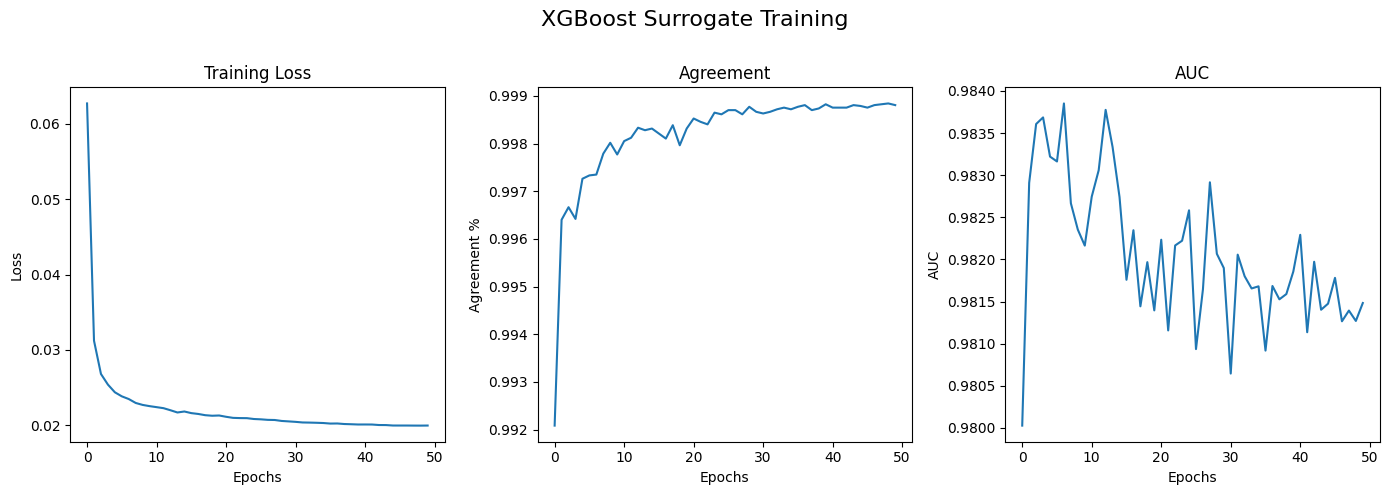

In [ ]:
#computing surrogate training graphs for xgboost

data = [xbg_surr_loss, xgb_surr_agr, xgb_surr_auc]
titles = ['Training Loss', 'Agreement', 'AUC']
ylabels = ['Loss', 'Agreement %', 'AUC']

fig, axs = plt.subplots(1, 3, figsize=(14,5))

for i in range(3):
    axs[i].plot(data[i])
    axs[i].set_title(titles[i])
    axs[i].set_xlabel('Epochs')
    axs[i].set_ylabel(ylabels[i])

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.suptitle('XGBoost Surrogate Training', fontsize=16)
plt.show()



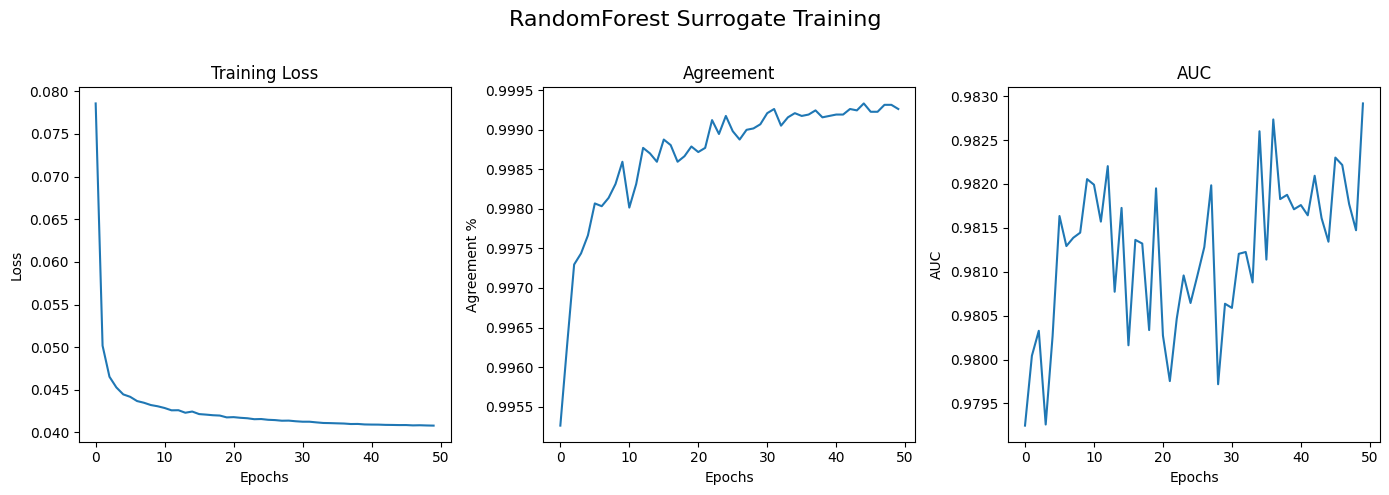

In [ ]:
#computing surrogate training graphs for RandomForest

data = [rf_surr_loss, rf_surr_agr, rf_surr_auc]
titles = ['Training Loss', 'Agreement', 'AUC']
ylabels = ['Loss', 'Agreement %', 'AUC']

fig, axs = plt.subplots(1, 3, figsize=(14,5))

for i in range(3):
    axs[i].plot(data[i])
    axs[i].set_title(titles[i])
    axs[i].set_xlabel('Epochs')
    axs[i].set_ylabel(ylabels[i])

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.suptitle('RandomForest Surrogate Training', fontsize=16)
plt.show()

## Entrainement du CTGAN

In [12]:
# On entraine notre CTGAN sur nos données réelle frauduleuse, avant augmentation des données par SMOT
print('Training CTGAN on real fraud samples...')

#Création du dataset
fraud_X = X[y == 1]
col_names = fraud_X.columns.tolist()
fraud_df = pd.DataFrame(fraud_X, columns=col_names)

#Initialisation
ctgan = CTGAN(epochs=150, verbose=False)

#Entraînement
ctgan.fit(fraud_df)

# Pertes
loss_values = ctgan.loss_values

gen_loss  = loss_values['Generator Loss']
disc_loss = loss_values['Discriminator Loss']

print('CTGAN training complete ✓')

Training CTGAN on real fraud samples...
CTGAN training complete ✓


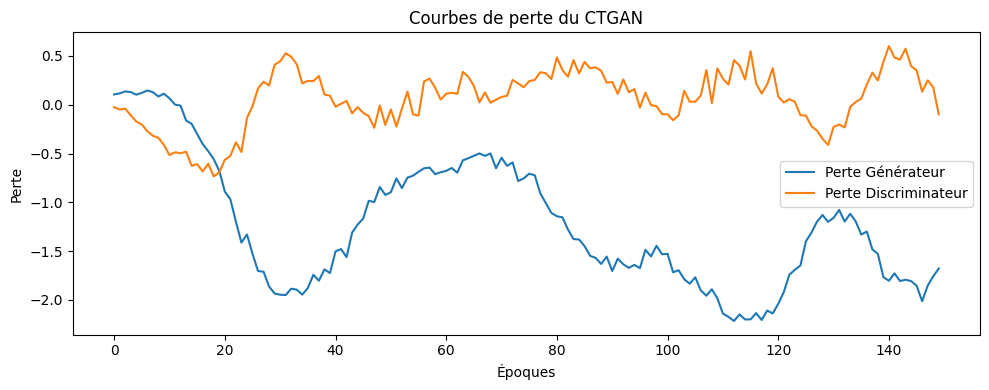

In [13]:
plt.figure(figsize=(10, 4))
plt.plot(gen_loss,  label='Perte Générateur')
plt.plot(disc_loss, label='Perte Discriminateur')
plt.xlabel('Époques')
plt.ylabel('Perte')
plt.title('Courbes de perte du CTGAN')
plt.legend()
plt.tight_layout()
plt.show()

## Génération de données adverserielles

In [ ]:
def generate_adversarial_examples(surrogate, ctgan_model, n_samples=1000):

    # Création de données adverserielles
    synthetic_df = ctgan_model.sample(n_samples)
    synthetic_np = synthetic_df.values.astype(np.float32)

    # Test sur le réseau de neurone qui mimic le comportement ddu modèle boîte noire
    surrogate.eval()
    with torch.no_grad():
        probs = surrogate(
            torch.tensor(synthetic_np, dtype=torch.float32).to(DEVICE)
        ).cpu().numpy()

    # On garde les données qui ont réussis a tromper le reseau de neurone
    evasion_mask = probs < 0.5
    adversarial_data  = synthetic_np[evasion_mask]
    return adversarial_data, probs, evasion_mask

In [ ]:
xgb_surrogate = SurrogateNet(X_bal.shape[1]).to(DEVICE)
xgb_surrogate.load_state_dict(torch.load('xgb_surrogate.pth'))

rf_surrogate = SurrogateNet(X_bal.shape[1]).to(DEVICE)
rf_surrogate.load_state_dict(torch.load('rf_surrogate.pth'))

<All keys matched successfully>

In [ ]:
# Génération sur XGBOOST

xgb_adv_data, xgb_surr_probs, xgb_evasion_mask = generate_adversarial_examples(
    xgb_surrogate, ctgan, n_samples=10000
)

print(f'  XGBoost surrogate evasion: {xgb_evasion_mask.mean()*100:.1f}%  ({xgb_evasion_mask.sum()}/10000)')

  XGBoost surrogate evasion: 36.3%  (3630/10000)


In [ ]:
# Génération sur RandomForest
rf_adv_data, rf_surr_probs, rf_evasion_mask = generate_adversarial_examples(
    rf_surrogate, ctgan, n_samples=10000
)
print(f'  RF surrogate evasion: {rf_evasion_mask.mean()*100:.1f}%  ({rf_evasion_mask.sum()}/10000)')


  RF surrogate evasion: 58.4%  (5841/10000)


- 36.6% des données généré par CTGAN on trompé le modèle substitut de XGBOOST

- 58.4% des données généré par CTGAN on trompé le modèle substitut de RandomForest

Nous allons utiliser ces données qui ont passer le test pour faire notre attaque sur nos modèle en boîte noire

## Attaque !!!! 💣 🥊

In [ ]:
def evaluate_attack(adversarial_X, bb_model, model_name):

    # Attack !!!!!
    probs  = bb_model.predict_proba(adversarial_X)[:, 1]
    preds  = (probs > 0.5).astype(int)

    # Check how many of our example went undetected
    transfer_evasion = (preds == 0).mean()
    print(f'  {model_name} transfer evasion rate : {transfer_evasion*100:.1f}%')
    print(f'  ({(preds==0).sum()} / {len(preds)} adversarial samples evaded detection)')
    return transfer_evasion, probs

In [ ]:
#Attaque sur XGBOOST

xgb_self_evasion, xgb_self_probs = evaluate_attack(xgb_adv_data, xgb_model, 'XGBoost')

print(' ')

#Attaque sur RandomForest

rf_self_evasion, rf_self_probs = evaluate_attack(rf_adv_data, rf_model, 'RandomForest')

  XGBoost transfer evasion rate : 92.4%
  (3353 / 3630 adversarial samples evaded detection)
 
  RandomForest transfer evasion rate : 95.2%
  (5563 / 5841 adversarial samples evaded detection)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
#Attaque croisé sur XGBOOST (données adverserielle de RandomForest sur XGBOOST)

rf_to_xgb_evasion, rf_to_xgb_probs = evaluate_attack(rf_adv_data, xgb_model, 'XGBoost')

print(' ')

#Attaque croisé sur RandomForest (données adverserielle de XGBOOST sur RandomForest)

xgb_to_rf_evasion, xgb_to_rf_probs = evaluate_attack(xgb_adv_data, rf_model, 'RandomForest')

  XGBoost transfer evasion rate : 84.9%
  (4958 / 5841 adversarial samples evaded detection)
 


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


  RandomForest transfer evasion rate : 98.6%
  (3579 / 3630 adversarial samples evaded detection)


## Visualisation des résultats

Plot saved → adversarial_tree_results.png


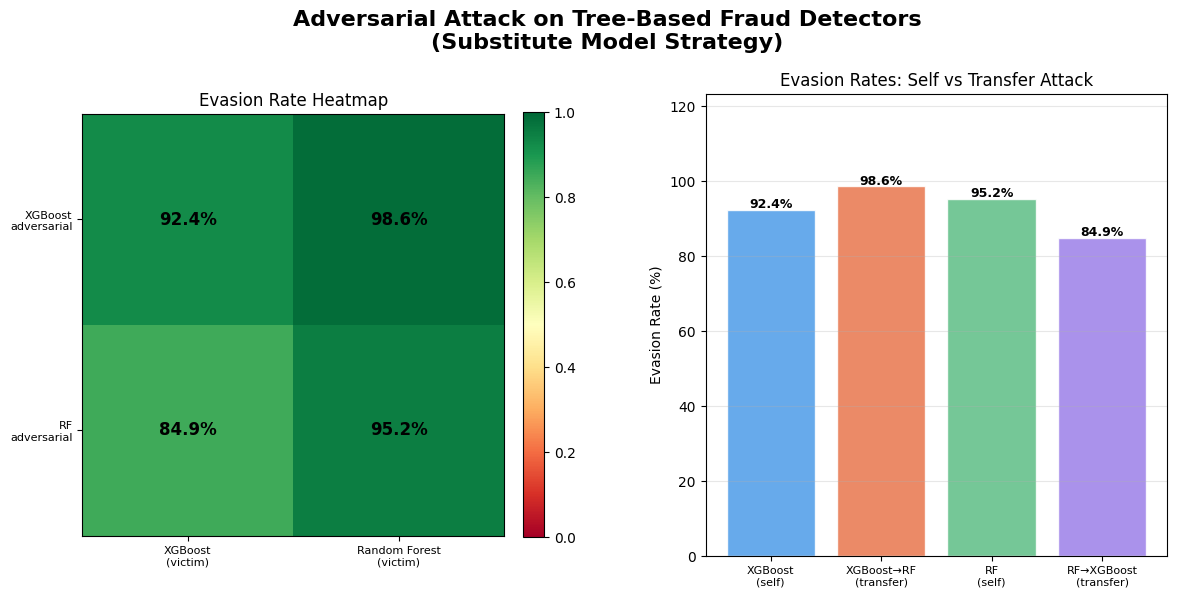

In [ ]:
fig = plt.figure(figsize=(14, 6))
fig.suptitle('Adversarial Attack on Tree-Based Fraud Detectors\n(Substitute Model Strategy)',
             fontsize=16, fontweight='bold', y=1.02)
gs = gridspec.GridSpec(1, 2, figure=fig, hspace=0.45, wspace=0.35)

BLUE   = '#4C9BE8'
ORANGE = '#E8764C'
GREEN  = '#5DBE85'
PURPLE = '#9B7FE8'

# ── Plot 1: Transfer evasion heatmap ──
ax1 = fig.add_subplot(gs[0, 0])
transfer_matrix = np.array([
    [xgb_self_evasion,   xgb_to_rf_evasion],
    [rf_to_xgb_evasion,  rf_self_evasion  ]
])
im = ax1.imshow(transfer_matrix, cmap='RdYlGn', vmin=0, vmax=1)
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xticklabels(['XGBoost\n(victim)', 'Random Forest\n(victim)'], fontsize=8)
ax1.set_yticklabels(['XGBoost\nadversarial', 'RF\nadversarial'], fontsize=8)
ax1.set_title('Evasion Rate Heatmap')
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f'{transfer_matrix[i,j]*100:.1f}%',
                 ha='center', va='center', fontweight='bold', fontsize=12,
                 color='white' if transfer_matrix[i,j] < 0.4 else 'black')
plt.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)

# ── Plot 2: Evasion rate comparison bar chart ──
ax2 = fig.add_subplot(gs[0, 1])
attack_labels = ['XGBoost\n(self)', 'XGBoost→RF\n(transfer)', 'RF\n(self)', 'RF→XGBoost\n(transfer)']
evasion_rates = [xgb_self_evasion, xgb_to_rf_evasion, rf_self_evasion, rf_to_xgb_evasion]
colors_bar    = [BLUE, ORANGE, GREEN, PURPLE]
bars = ax2.bar(attack_labels, [r*100 for r in evasion_rates], color=colors_bar, alpha=0.85, edgecolor='white')
for bar, val in zip(bars, evasion_rates):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val*100:.1f}%', ha='center', fontweight='bold', fontsize=9)
ax2.set_title('Evasion Rates: Self vs Transfer Attack')
ax2.set_ylabel('Evasion Rate (%)')
ax2.set_ylim(0, max([r*100 for r in evasion_rates]) * 1.2 + 5)
ax2.grid(axis='y', alpha=0.3)
ax2.tick_params(axis='x', labelsize=8)

plt.savefig('adversarial_tree_results.png', dpi=150, bbox_inches='tight')
print('Plot saved → adversarial_tree_results.png')
plt.show()

In [ ]:
print('\n── Evasion Rates ──')
print(f'  XGBoost adversarial → XGBoost (self)     : {xgb_self_evasion*100:.1f}%')
print(f'  XGBoost adversarial → Random Forest (transfer) : {xgb_to_rf_evasion*100:.1f}%')
print(f'  RF adversarial → Random Forest (self)    : {rf_self_evasion*100:.1f}%')
print(f'  RF adversarial → XGBoost (transfer)      : {rf_to_xgb_evasion*100:.1f}%')

print('\n── Interpretation ──')
more_robust = 'XGBoost' if rf_self_evasion > xgb_self_evasion else 'Random Forest'
print(f'  More robust to adversarial attack: {more_robust}')

avg_transfer = (xgb_to_rf_evasion + rf_to_xgb_evasion) / 2
print(f'  Average cross-model transfer rate: {avg_transfer*100:.1f}%')
if avg_transfer > 0.3:
    print('  → High transferability: adversarial examples generalise across models')
else:
    print('  → Low transferability: adversarial examples are model-specific')
print('=' * 60)


── Evasion Rates ──
  XGBoost adversarial → XGBoost (self)     : 92.4%
  XGBoost adversarial → Random Forest (transfer) : 98.6%
  RF adversarial → Random Forest (self)    : 95.2%
  RF adversarial → XGBoost (transfer)      : 84.9%

── Interpretation ──
  More robust to adversarial attack: XGBoost
  Average cross-model transfer rate: 91.7%
  → High transferability: adversarial examples generalise across models


## BONUS : Attaque boîte noire par transfert sur des architechtures modernes

Maintenant que nous avons vu que les données adverserielles ciblant XGBOOST se transfert le mieux, esseyons d'attaque d'autre architecture moderne avec ces mêmes données.

Ici nous allons attaquer :  

- ResNet
- GANDLF

In [ ]:
!pip install pytorch-tabular

import gc
from pytorch_tabular import TabularModel
from pytorch_tabular.config import DataConfig, TrainerConfig, OptimizerConfig
from pytorch_tabular.models import (
    FTTransformerConfig,
    TabTransformerConfig,
    TabNetModelConfig,
    NodeConfig,
    CategoryEmbeddingModelConfig,
    GANDALFConfig,
)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.8/165.8 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.8/159.8 kB 19.1 MB/s eta 0:00:00


In [ ]:
feature_names = X_bal.columns.tolist()

# ── Prepare dataframes (pytorch-tabular expects DataFrames) ──
train_df       = X_bal.copy()
train_df['Class'] = y_bal.values

test_df        = X_test.copy()
test_df['Class'] = y_test.values

adv_df         = pd.DataFrame(xgb_adv_data, columns=feature_names)
adv_df['Class'] = 1  # all true label = Fraud

# ── Shared configs ──
data_config = DataConfig(
    target          = ['Class'],
    continuous_cols = feature_names,
    categorical_cols= [],
)

trainer_config = TrainerConfig(
    max_epochs    = 20,
    batch_size    = 1024,
    early_stopping= 'valid_loss',
    early_stopping_patience = 3,
    checkpoints   = None,
    load_best     = True,
    progress_bar  = 'simple',
    trainer_kwargs= {'enable_model_summary': False},
)

optimizer_config = OptimizerConfig()

# ── Model configs ──
model_configs = {
    'ResNet'         : CategoryEmbeddingModelConfig(task='classification'),
    'GANDALF'        : GANDALFConfig(task='classification'),
}

# ── Train & evaluate each model ──
dl_results = {}

for name, model_config in model_configs.items():
    print(f'\n{"="*50}')
    print(f'Training {name}...')

    model = TabularModel(
        data_config     = data_config,
        model_config    = model_config,
        optimizer_config= optimizer_config,
        trainer_config  = trainer_config,
    )

    model.fit(train=train_df, validation=test_df)

    # Clean performance
    clean_preds = model.predict(test_df)
    clean_acc   = accuracy_score(test_df['Class'], clean_preds['Class_prediction'])
    clean_auc   = roc_auc_score(test_df['Class'],  clean_preds['Class_1_probability'])

    # Adversarial performance
    adv_preds     = model.predict(adv_df)
    evasion_rate  = (adv_preds['Class_prediction'] == 0).mean()  # predicted as Legit

    print(f'{name} → Clean Acc: {clean_acc:.4f} | AUC: {clean_auc:.4f} | Evasion: {evasion_rate*100:.1f}%')

    dl_results[name] = {
        'clean_acc'    : clean_acc,
        'clean_auc'    : clean_auc,
        'evasion_rate' : evasion_rate,
    }

2026-04-07 03:39:50,095 - {pytorch_tabular.tabular_model:145} - INFO - Experiment Tracking is turned off
INFO:lightning_fabric.utilities.seed:Seed set to 42
2026-04-07 03:39:50,166 - {pytorch_tabular.tabular_model:547} - INFO - Preparing the DataLoaders



Training ResNet...


2026-04-07 03:39:50,258 - {pytorch_tabular.tabular_datamodule:527} - INFO - Setting up the datamodule for classification task
2026-04-07 03:39:51,341 - {pytorch_tabular.tabular_model:598} - INFO - Preparing the Model: CategoryEmbeddingModel
2026-04-07 03:39:51,510 - {pytorch_tabular.tabular_model:341} - INFO - Preparing the Trainer
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
2026-04-07 03:39:51,633 - {pytorch_tabular.tabular_model:677} - INFO - Training Started
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

2026-04-07 03:42:26,015 - {pytorch_tabular.tabular_model:690} - INFO - Training the model completed
2026-04-07 03:42:26,016 - {pytorch_tabular.tabular_model:1541} - WARNING - No best model available to load. Checkpoint Callback needs to be enabled for this to work
2026-04-07 03:42:29,062 - {pytorch_tabular.tabular_model:145} - INFO - Experiment Tracking is turned off
INFO:lightning_fabric.utilities.seed:Seed set to 42
2026-04-07 03:42:29,122 - {pytorch_tabular.tabular_model:547} - INFO - Preparing the DataLoaders
2026-04-07 03:42:29,190 - {pytorch_tabular.tabular_datamodule:527} - INFO - Setting up the datamodule for classification task


... (2 outputs left out)

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

2026-04-07 03:44:44,931 - {pytorch_tabular.tabular_model:690} - INFO - Training the model completed
2026-04-07 03:44:44,932 - {pytorch_tabular.tabular_model:1541} - WARNING - No best model available to load. Checkpoint Callback needs to be enabled for this to work


GANDALF → Clean Acc: 0.9965 | AUC: 0.9672 | Evasion: 43.0%


Plot saved → dl_transfer_results.png


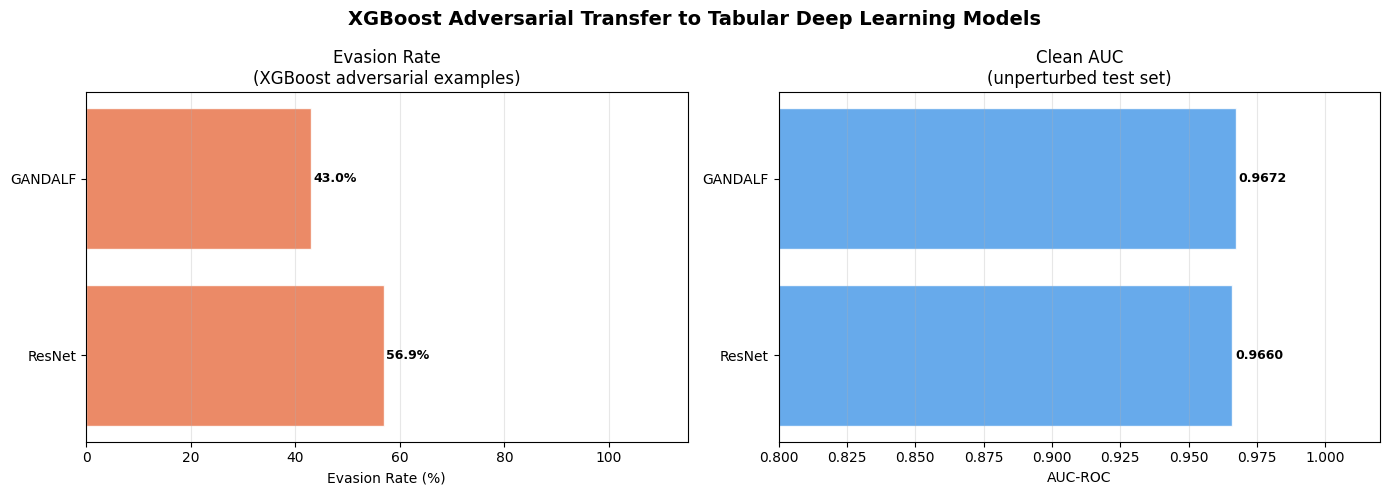

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('XGBoost Adversarial Transfer to Tabular Deep Learning Models',
             fontsize=14, fontweight='bold')

BLUE   = '#4C9BE8'
ORANGE = '#E8764C'

names         = list(dl_results.keys())
evasion_rates = [dl_results[m]['evasion_rate'] * 100 for m in names]
clean_aucs    = [dl_results[m]['clean_auc']          for m in names]

# ── Evasion rates ──
bars = axes[0].barh(names, evasion_rates, color=ORANGE, alpha=0.85, edgecolor='white')
for bar, val in zip(bars, evasion_rates):
    axes[0].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                 f'{val:.1f}%', va='center', fontweight='bold', fontsize=9)
axes[0].set_title('Evasion Rate\n(XGBoost adversarial examples)')
axes[0].set_xlabel('Evasion Rate (%)')
axes[0].set_xlim(0, 115)
axes[0].grid(axis='x', alpha=0.3)

# ── Clean AUC ──
bars2 = axes[1].barh(names, clean_aucs, color=BLUE, alpha=0.85, edgecolor='white')
for bar, val in zip(bars2, clean_aucs):
    axes[1].text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontweight='bold', fontsize=9)
axes[1].set_title('Clean AUC\n(unperturbed test set)')
axes[1].set_xlabel('AUC-ROC')
axes[1].set_xlim(0.8, 1.02)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('dl_transfer_results.png', dpi=150, bbox_inches='tight')
print('Plot saved → dl_transfer_results.png')
plt.show()